---
## 🎛️ Κελί 1 — Knobs (μόνο αυτό αλλάζεις!)
Όλες οι παράμετροι του lab είναι εδώ. **Μην αλλάζεις τίποτα σε άλλα κελιά.**

In [15]:
# ── KNOBS ────────────────────────────────────────────────────────────────
DATA_PATH    = 'euroleague_players.csv'  # path στο dataset
SEASON       = 'E2025'       # σεζόν ανάλυσης (π.χ. 'E2024', 'E2023', 'ALL')
TOP_N        = 15            # πόσους κορυφαίους παίκτες εμφανίζεις στα bar charts
MIN_GAMES    = 10            # ελάχιστα παιχνίδια για να συμπεριληφθεί παίκτης
METRIC       = 'valuation_per_game'  # κύρια μετρική: valuation_per_game, points_per_game, assists_per_game
RANDOM_STATE = 42            # για αναπαραγωγιμότητα
# ─────────────────────────────────────────────────────────────────────────

# 🏀 Lecture 0 — EDA: EuroLeague Player Stats
**Εισαγωγή στην Τεχνητή Νοημοσύνη** | MSc Applied Informatics | Harokopio University

Σε αυτό το εργαστήριο εξερευνούμε πραγματικά δεδομένα από το EuroLeague (2007–2025).  
Δεν εκπαιδεύουμε ακόμα μοντέλο — μαθαίνουμε να **βλέπουμε** τα δεδομένα.

**Στόχοι:**
- Φόρτωση και πρώτη επιθεώρηση dataset με `pandas`
- Οπτικοποίηση κατανομών και σχέσεων με `seaborn` / `matplotlib`
- Εξαγωγή απλών συμπερασμάτων από τα δεδομένα
- Κατανόηση γιατί η EDA είναι **πάντα το πρώτο βήμα** πριν το ML

---
## 📦 Κελί 2 — Imports

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Στυλ γραφημάτων
sns.set_theme(style='whitegrid', palette='muted', font_scale=1.05)
plt.rcParams['figure.dpi'] = 110

print('✅ Imports OK')

✅ Imports OK


---
## 📂 Κελί 3 — Φόρτωση & Πρώτη Επιθεώρηση
Πριν κάνεις οτιδήποτε, **κοίτα τα δεδομένα σου**.

In [17]:
# Φόρτωση
df_all = pd.read_csv(DATA_PATH)

print(f'📊 Συνολικές εγγραφές: {len(df_all):,}')
print(f'📅 Σεζόν διαθέσιμες: {sorted(df_all["season_code"].unique())}')
print(f'🏀 Μοναδικοί παίκτες: {df_all["player"].nunique():,}')
print(f'🏟️  Μοναδικές ομάδες: {df_all["team_id"].nunique()}')
print(f'📋 Στήλες: {df_all.shape[1]}')
print()

# Επιλογή σεζόν
if SEASON == 'ALL':
    df = df_all.copy()
    print(f'🔍 Ανάλυση: ΟΛΕς οι σεζόν ({len(df):,} εγγραφές)')
else:
    df = df_all[df_all['season_code'] == SEASON].copy()
    print(f'🔍 Ανάλυση σεζόν: {SEASON} → {len(df)} παίκτες')

# Φίλτρο ελάχιστων αγώνων
df = df[df['games_played'] >= MIN_GAMES].copy()
print(f'✂️  Μετά φίλτρο (>= {MIN_GAMES} αγώνες): {len(df)} παίκτες')

📊 Συνολικές εγγραφές: 6,307
📅 Σεζόν διαθέσιμες: ['E2007', 'E2008', 'E2009', 'E2010', 'E2011', 'E2012', 'E2013', 'E2014', 'E2015', 'E2016', 'E2017', 'E2018', 'E2019', 'E2020', 'E2021', 'E2022', 'E2023', 'E2024', 'E2025']
🏀 Μοναδικοί παίκτες: 2,362
🏟️  Μοναδικές ομάδες: 66
📋 Στήλες: 50

🔍 Ανάλυση σεζόν: E2025 → 358 παίκτες
✂️  Μετά φίλτρο (>= 10 αγώνες): 281 παίκτες


In [18]:
# Πρώτες 5 γραμμές
cols_show = ['player', 'team_id', 'games_played', 'minutes_per_game',
             'points_per_game', 'assists_per_game', 'total_rebounds_per_game',
             'valuation_per_game', 'three_points_percentage']
df[cols_show].head(8)

,player,team_id,games_played,minutes_per_game,points_per_game,assists_per_game,total_rebounds_per_game,valuation_per_game,three_points_percentage
7,"ABALDE, ALBERTO",MAD,36.0,15.85,4.75,1.39,1.58,4.11,0.493
14,"ABASS, AWUDU",DUB,31.0,16.38,3.19,0.55,1.52,2.35,0.333
62,"AJINCA, MELVIN",ASV,31.0,17.72,6.00,0.55,1.81,3.39,0.327
65,"AKELE, NICOLA",VIR,27.0,9.90,2.48,0.67,2.04,3.19,0.333
99,"ALSTON JR., DERRICK",VIR,37.0,22.43,10.03,1.41,2.65,8.70,0.447
134,"ANDERSON, JUSTIN",DUB,33.0,23.48,6.12,1.30,3.00,6.33,0.409
150,"ANGOLA, BRAIAN",ASV,15.0,24.37,15.33,3.87,3.00,17.87,0.320
222,"ATAMNA, ADAM",ASV,17.0,10.40,1.59,1.18,1.24,0.47,0.132


In [19]:
# Στατιστικά περίληψης
df[['points_per_game', 'assists_per_game', 'total_rebounds_per_game',
    'valuation_per_game', 'three_points_percentage']].describe().round(2)

,points_per_game,assists_per_game,total_rebounds_per_game,valuation_per_game,three_points_percentage
count,281.00,281.00,281.00,281.00,281.00
mean,7.69,1.71,2.75,8.20,0.31
std,4.17,1.41,1.38,4.69,0.14
min,0.00,0.18,0.36,-0.45,0.00
25%,4.56,0.67,1.73,4.56,0.29
50%,7.05,1.27,2.49,7.65,0.34
75%,10.70,2.25,3.55,11.14,0.39
max,19.44,7.53,7.14,23.12,0.80


In [20]:
# Τύποι δεδομένων & missing values
missing = df.isnull().sum()
missing = missing[missing > 0]
if len(missing) > 0:
    print('⚠️  Στήλες με missing values:')
    print(missing)
else:
    print('✅ Δεν υπάρχουν missing values στις κύριες στήλες')

print(f'\nΤύποι δεδομένων:')
print(df[cols_show].dtypes)

✅ Δεν υπάρχουν missing values στις κύριες στήλες

Τύποι δεδομένων:
player                         str
team_id                        str
games_played               float64
minutes_per_game           float64
points_per_game            float64
assists_per_game           float64
total_rebounds_per_game    float64
valuation_per_game         float64
three_points_percentage    float64
dtype: object


---
## 📊 Κελί 4 — Κορυφαίοι Παίκτες (Bar Chart)
Ποιοι έχουν το υψηλότερο **valuation per game** (= PIR, Performance Index Rating);

> **Τι είναι το PIR;**  
> PIR = (Pts + Reb + Ast + Stl + Blk + Fouls Drawn) − (FGA missed + FTA missed + TO + Fouls + Blks against)

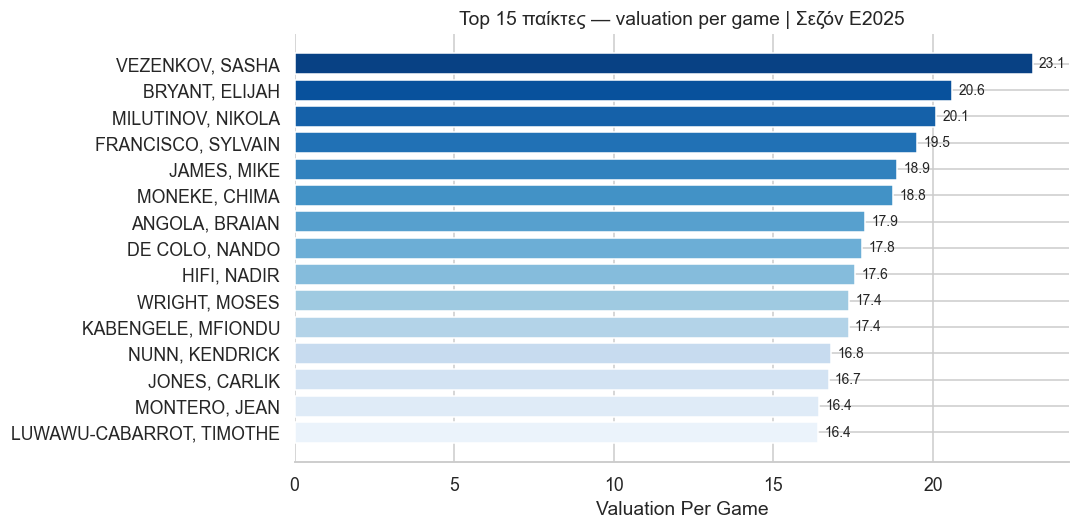

                  player team_id  valuation_per_game  games_played
         VEZENKOV, SASHA     OLY               23.12          34.0
          BRYANT, ELIJAH     HTA               20.59          34.0
       MILUTINOV, NIKOLA     OLY               20.09          35.0
      FRANCISCO, SYLVAIN     ZAL               19.50          38.0
             JAMES, MIKE     MCO               18.88          34.0
           MONEKE, CHIMA     RED               18.76          34.0
          ANGOLA, BRAIAN     ASV               17.87          15.0
          DE COLO, NANDO     ASV               17.77          13.0
             HIFI, NADIR     PRS               17.57          37.0
           WRIGHT, MOSES     ZAL               17.37          38.0
      KABENGELE, MFIONDU     DUB               17.36          36.0
          NUNN, KENDRICK     PAN               16.81          31.0
           JONES, CARLIK     PAR               16.73          15.0
           MONTERO, JEAN     PAM               16.44          

In [21]:
top = df.nlargest(TOP_N, METRIC)[['player', 'team_id', METRIC, 'games_played']].copy()

fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.barh(top['player'], top[METRIC],
               color=sns.color_palette('Blues_r', TOP_N))

# Ετικέτες τιμών
for bar, val in zip(bars, top[METRIC]):
    ax.text(val + 0.2, bar.get_y() + bar.get_height()/2,
            f'{val:.1f}', va='center', fontsize=9)

ax.set_xlabel(METRIC.replace('_', ' ').title())
ax.set_title(f'Top {TOP_N} παίκτες — {METRIC.replace("_"," ")} | Σεζόν {SEASON}')
ax.invert_yaxis()
sns.despine(left=True)
plt.tight_layout()
plt.show()

print(top.to_string(index=False))

---
## 📈 Κελί 5 — Κατανομή Points per Game (Histogram + Boxplot)
Πώς κατανέμονται τα points; Είναι κανονική κατανομή; Υπάρχουν outliers;

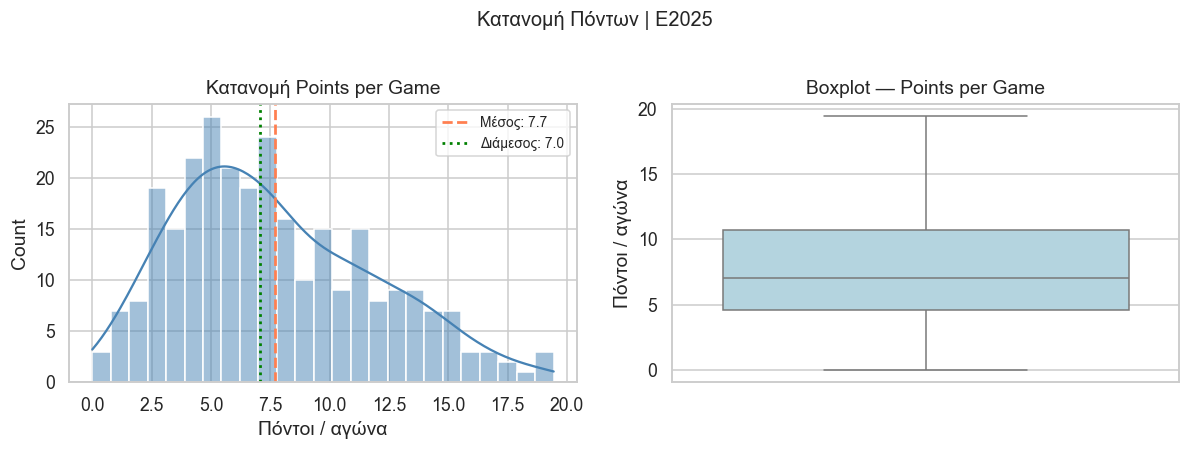

📌 Outliers (πάνω από Q3+1.5*IQR = 19.9):
Empty DataFrame
Columns: [player, team_id, points_per_game]
Index: []


In [22]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# Histogram
sns.histplot(df['points_per_game'], bins=25, kde=True,
             color='steelblue', ax=axes[0])
axes[0].axvline(df['points_per_game'].mean(), color='coral',
                linestyle='--', linewidth=1.8, label=f'Μέσος: {df["points_per_game"].mean():.1f}')
axes[0].axvline(df['points_per_game'].median(), color='green',
                linestyle=':', linewidth=1.8, label=f'Διάμεσος: {df["points_per_game"].median():.1f}')
axes[0].legend(fontsize=9)
axes[0].set_title('Κατανομή Points per Game')
axes[0].set_xlabel('Πόντοι / αγώνα')

# Boxplot
sns.boxplot(y=df['points_per_game'], color='lightblue', ax=axes[1])
axes[1].set_title('Boxplot — Points per Game')
axes[1].set_ylabel('Πόντοι / αγώνα')

plt.suptitle(f'Κατανομή Πόντων | {SEASON}', fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

# Outliers
q1, q3 = df['points_per_game'].quantile([0.25, 0.75])
iqr = q3 - q1
outliers = df[df['points_per_game'] > q3 + 1.5*iqr][['player','team_id','points_per_game']]
print(f'📌 Outliers (πάνω από Q3+1.5*IQR = {q3+1.5*iqr:.1f}):')
print(outliers.sort_values('points_per_game', ascending=False).to_string(index=False))

---
## 🔗 Κελί 6 — Σχέση Assists vs Points (Scatter Plot)
Παίκτες που σκοράρουν πολύ, κάνουν και πολλές ασίστ; Ή είναι αντίθετη σχέση;

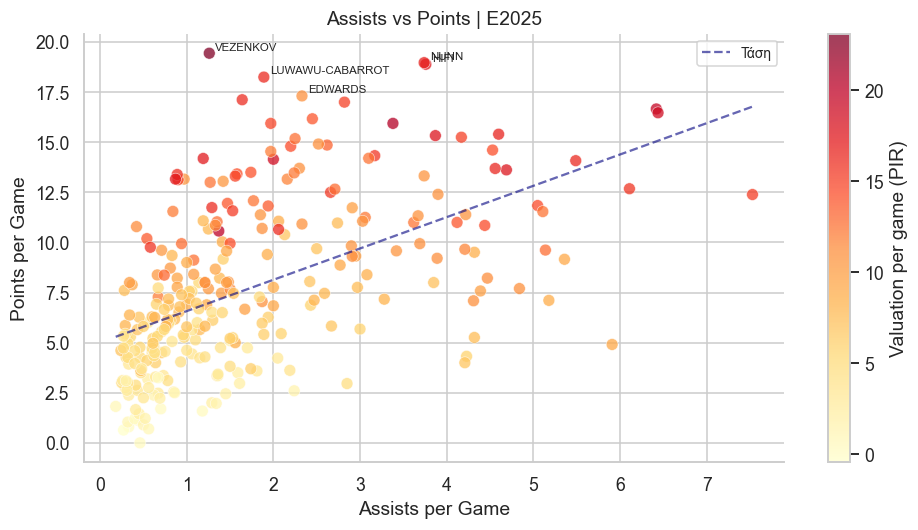

📌 Pearson correlation (assists, points): r = 0.529
   → Θετική σχέση


In [23]:
fig, ax = plt.subplots(figsize=(9, 5))

scatter = ax.scatter(
    df['assists_per_game'],
    df['points_per_game'],
    c=df['valuation_per_game'],
    cmap='YlOrRd',
    alpha=0.75,
    edgecolors='white',
    linewidth=0.4,
    s=60
)
plt.colorbar(scatter, ax=ax, label='Valuation per game (PIR)')

# Γραμμή τάσης
z = np.polyfit(df['assists_per_game'].dropna(), df['points_per_game'].dropna(), 1)
p = np.poly1d(z)
xs = np.linspace(df['assists_per_game'].min(), df['assists_per_game'].max(), 100)
ax.plot(xs, p(xs), 'navy', linewidth=1.5, linestyle='--', alpha=0.6, label='Τάση')

# Ετικέτες top παικτών
top5 = df.nlargest(5, 'points_per_game')
for _, row in top5.iterrows():
    ax.annotate(row['player'].split(',')[0],
                (row['assists_per_game'], row['points_per_game']),
                fontsize=7.5, xytext=(4, 2), textcoords='offset points')

ax.set_xlabel('Assists per Game')
ax.set_ylabel('Points per Game')
ax.set_title(f'Assists vs Points | {SEASON}')
ax.legend(fontsize=9)
sns.despine()
plt.tight_layout()
plt.show()

# Pearson correlation
corr = df['assists_per_game'].corr(df['points_per_game'])
print(f'📌 Pearson correlation (assists, points): r = {corr:.3f}')
print('   →', 'Θετική σχέση' if corr > 0.2 else 'Αδύναμη / αρνητική σχέση')

---
## 🌍 Κελί 7 — Εξέλιξη 3-pointers ανά Σεζόν
Πώς έχει αλλάξει το παιχνίδι από το 2007 ως σήμερα;

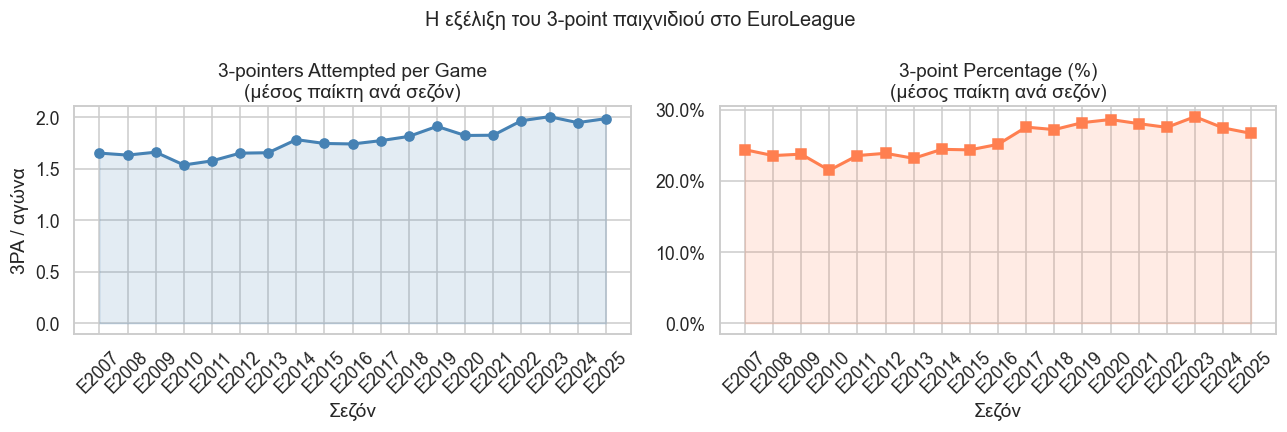

📌 3PA/game: 1.65 (E2007) → 1.99 (E2025)
   Αύξηση: 20%


In [24]:
# Μέσος όρος 3-pointers attempted per game ανά σεζόν
trend = (df_all
         .groupby('season_code')[['three_points_attempted_per_game',
                                   'three_points_percentage']]
         .mean()
         .reset_index()
         .sort_values('season_code'))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# 3PA per game over time
axes[0].plot(trend['season_code'], trend['three_points_attempted_per_game'],
             marker='o', color='steelblue', linewidth=2)
axes[0].fill_between(trend['season_code'],
                     trend['three_points_attempted_per_game'],
                     alpha=0.15, color='steelblue')
axes[0].set_title('3-pointers Attempted per Game\n(μέσος παίκτη ανά σεζόν)')
axes[0].set_xlabel('Σεζόν')
axes[0].tick_params(axis='x', rotation=45)
axes[0].set_ylabel('3PA / αγώνα')

# 3P% over time
axes[1].plot(trend['season_code'], trend['three_points_percentage'] * 100,
             marker='s', color='coral', linewidth=2)
axes[1].fill_between(trend['season_code'],
                     trend['three_points_percentage'] * 100,
                     alpha=0.15, color='coral')
axes[1].set_title('3-point Percentage (%)\n(μέσος παίκτη ανά σεζόν)')
axes[1].set_xlabel('Σεζόν')
axes[1].tick_params(axis='x', rotation=45)
axes[1].yaxis.set_major_formatter(mticker.FormatStrFormatter('%.1f%%'))

plt.suptitle('Η εξέλιξη του 3-point παιχνιδιού στο EuroLeague', fontsize=13)
plt.tight_layout()
plt.show()

print(f'📌 3PA/game: {trend["three_points_attempted_per_game"].iloc[0]:.2f} (E2007) → {trend["three_points_attempted_per_game"].iloc[-1]:.2f} (E2025)')
print(f'   Αύξηση: {(trend["three_points_attempted_per_game"].iloc[-1] / trend["three_points_attempted_per_game"].iloc[0] - 1)*100:.0f}%')

---
## 🏆 Κελί 8 — Κορυφαίες Ομάδες
Ποιες ομάδες έχουν τον μεγαλύτερο μέσο PIR στη σεζόν μας;

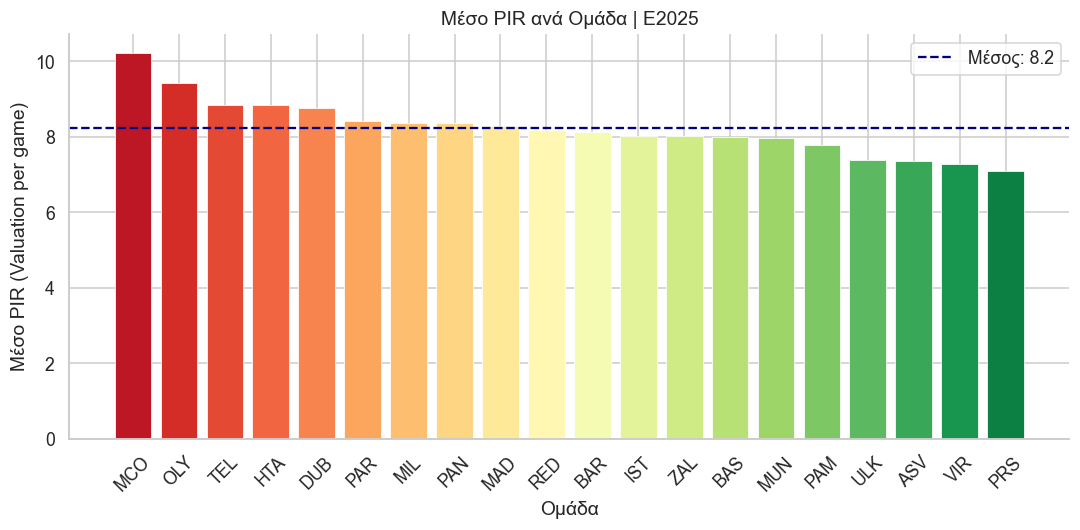

team_id  μέσο_PIR  μέσοι_πόντοι  παίκτες
    MCO     10.22          9.01       11
    OLY      9.43          8.01       14
    TEL      8.84          8.32       14
    HTA      8.83          8.24       12
    DUB      8.75          8.22       14
    PAR      8.42          8.29       16
    MIL      8.36          7.62       14
    PAN      8.36          7.69       15
    MAD      8.28          7.30       13
    RED      8.18          7.69       14


In [25]:
team_stats = (df.groupby('team_id')
              .agg(
                  μέσο_PIR=('valuation_per_game', 'mean'),
                  μέσοι_πόντοι=('points_per_game', 'mean'),
                  παίκτες=('player', 'count')
              )
              .round(2)
              .sort_values('μέσο_PIR', ascending=False)
              .reset_index())

fig, ax = plt.subplots(figsize=(10, 5))
palette = sns.color_palette('RdYlGn', len(team_stats))
bars = ax.bar(team_stats['team_id'], team_stats['μέσο_PIR'],
              color=palette, edgecolor='white', linewidth=0.5)

ax.set_xlabel('Ομάδα')
ax.set_ylabel('Μέσο PIR (Valuation per game)')
ax.set_title(f'Μέσο PIR ανά Ομάδα | {SEASON}')
ax.tick_params(axis='x', rotation=45)
ax.axhline(team_stats['μέσο_PIR'].mean(), color='navy',
           linestyle='--', linewidth=1.5,
           label=f'Μέσος: {team_stats["μέσο_PIR"].mean():.1f}')
ax.legend()
sns.despine()
plt.tight_layout()
plt.show()

print(team_stats.head(10).to_string(index=False))

---
## 🔥 Κελί 9 — Heatmap Συσχετίσεων
Ποιες μεταβλητές συσχετίζονται μεταξύ τους; Αυτό μας δείχνει ποιες features είναι **χρήσιμες** για ML.

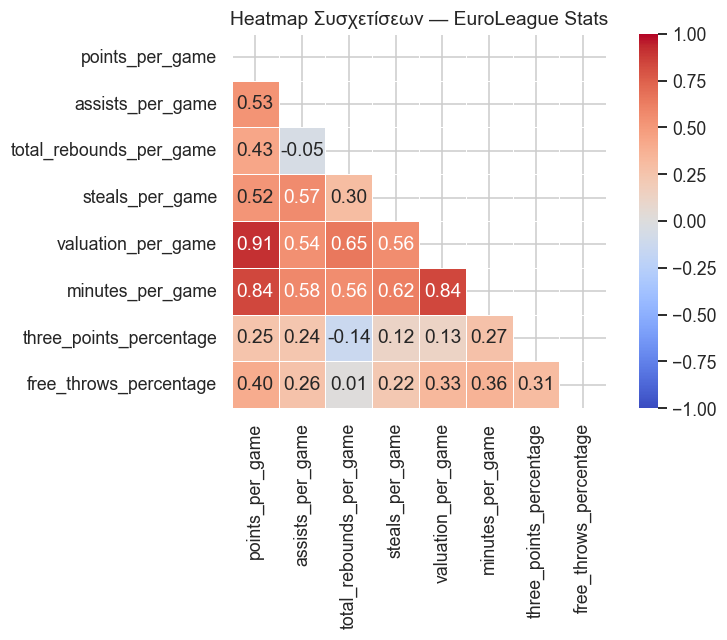

📌 Συσχετίσεις με PIR (valuation_per_game):
points_per_game            0.91
minutes_per_game           0.84
total_rebounds_per_game    0.65
steals_per_game            0.56
assists_per_game           0.54
free_throws_percentage     0.33
three_points_percentage    0.13


In [26]:
corr_cols = ['points_per_game', 'assists_per_game', 'total_rebounds_per_game',
             'steals_per_game', 'valuation_per_game', 'minutes_per_game',
             'three_points_percentage', 'free_throws_percentage']

corr_matrix = df[corr_cols].corr().round(2)

fig, ax = plt.subplots(figsize=(8, 6))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))  # μόνο το κάτω τρίγωνο
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f',
            cmap='coolwarm', center=0, vmin=-1, vmax=1,
            square=True, linewidths=0.5, ax=ax)
ax.set_title('Heatmap Συσχετίσεων — EuroLeague Stats')
plt.tight_layout()
plt.show()

# Ισχυρότερες συσχετίσεις με το PIR
pir_corr = corr_matrix['valuation_per_game'].drop('valuation_per_game').sort_values(ascending=False)
print('📌 Συσχετίσεις με PIR (valuation_per_game):')
print(pir_corr.to_string())

---
## 🌉 Κελί 10 — Γέφυρα προς ML
Τώρα που **βλέπουμε** τα δεδομένα, ορίζουμε το επόμενο ερώτημα:

> **Μπορούμε να προβλέψουμε αν ένας παίκτης είναι starter (games_started > games_played/2) από τα στατιστικά του;**

Αυτό θα είναι το **classification πρόβλημα του Lecture 1**.

📊 Κατανομή target variable (is_starter):
   Starters (1):     116 παίκτες (41.3%)
   Non-starters (0): 165 παίκτες (58.7%)

📌 Μέσοι όροι ανά κατηγορία:
             points_per_game  assists_per_game  minutes_per_game  valuation_per_game
Non-starter             5.91              1.37             14.86                6.15
Starter                10.22              2.21             22.57               11.12


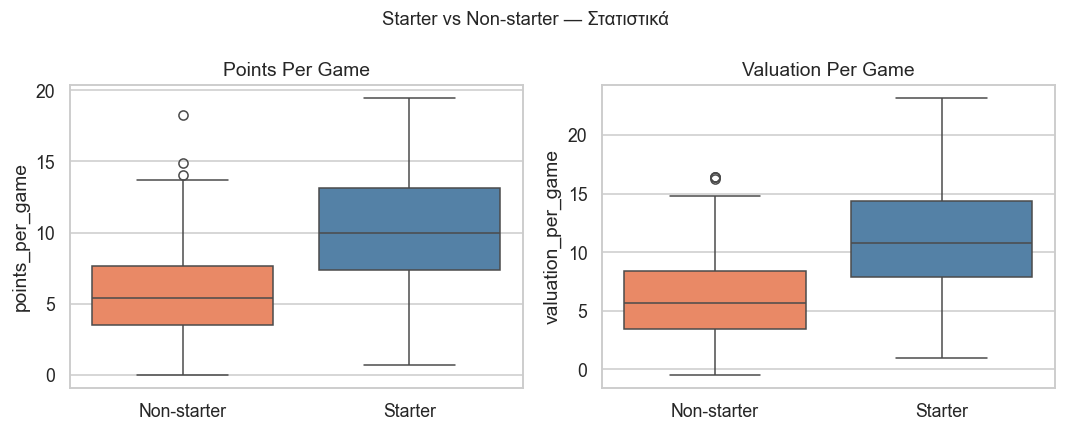


💡 Αυτό το ερώτημα θα το λύσουμε με ML στο Lecture 1!


In [27]:
# Δημιουργούμε target variable
df['is_starter'] = (df['games_started'] > df['games_played'] / 2).astype(int)

starter_counts = df['is_starter'].value_counts()
print('📊 Κατανομή target variable (is_starter):')
print(f'   Starters (1):     {starter_counts.get(1, 0):3d} παίκτες ({starter_counts.get(1,0)/len(df)*100:.1f}%)')
print(f'   Non-starters (0): {starter_counts.get(0, 0):3d} παίκτες ({starter_counts.get(0,0)/len(df)*100:.1f}%)')
print()

# Διαφορές στατιστικών ανά κατηγορία
comparison = df.groupby('is_starter')[['points_per_game','assists_per_game',
                                        'minutes_per_game','valuation_per_game']].mean().round(2)
comparison.index = ['Non-starter', 'Starter']
print('📌 Μέσοι όροι ανά κατηγορία:')
print(comparison.to_string())

# Οπτικοποίηση
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, col in zip(axes, ['points_per_game', 'valuation_per_game']):
    sns.boxplot(x='is_starter', y=col, data=df, palette=['coral', 'steelblue'], ax=ax)
    ax.set_xticklabels(['Non-starter', 'Starter'])
    ax.set_title(f'{col.replace("_"," ").title()}')
    ax.set_xlabel('')

plt.suptitle('Starter vs Non-starter — Στατιστικά', fontsize=12)
plt.tight_layout()
plt.show()

print()
print('💡 Αυτό το ερώτημα θα το λύσουμε με ML στο Lecture 1!')

---
## ❓ Κελί 11 — Ερωτήσεις Αξιολόγησης
Απάντησε σε **Markdown** (διπλό κλικ στο κελί για επεξεργασία).

### Ερώτηση 1
Κοιτώντας το histogram των πόντων, η κατανομή είναι κανονική (normal) ή skewed; Τι σημαίνει αυτό για τους παίκτες του EuroLeague;

**Απάντηση:**  
Το ιστόγραμμα δείχνει ότι η πλειοψηφία των παικτών σκοράρει συνήθως μεταξύ 3 και 10 πόντων. Στον οριζόντιο άξονα έχουμε τους πόντους και στον κάθετο τους παίχτες. Η πράσινη γραμμή (7.0) αντιπροσωπεύει τη διάμεσο, χωρίζοντας δηλαδή τους παίκτες ακριβώς στη μέση, ενώ η πορτοκαλί γραμμή (7.7) δείχνει τον συνολικό μέσο όρο. Το θηκόγραμμα (boxplot) απεικονίζει τα ίδια ακριβώς δεδομένα, εστιάζοντας στο πού συγκεντρώνεται το κύριο "δείγμα" των στατιστικών. Το γαλάζιο κουτί περικλείει το μεσαίο 50% των παικτών, δηλαδή τους average σκόρερ, ενώ η οριζόντια γραμμή στο εσωτερικό του δείχνει ξανά τη διάμεσο στους 7.0 πόντους. Τέλος, οι κάθετες γραμμές που προεξέχουν πάνω και κάτω από το κουτί ("μουστάκια") δείχνουν το ελάχιστου και μέγιστου σκοράρισμα, τα οποία κυμαίνονται από 0 μέχρι περίπου 20 πόντους. Αυτή η ασυμμετρία προκύπτει επειδή υπάρχουν ελάχιστοι παίκτες που βάζουν πάρα πολλούς πόντους (15-20), οι οποίοι τραβάνε μαθηματικά τον μέσο όρο προς τα πάνω. Κοιτώντας το διάγραμμα των πόντων παρατηρούμε ότι η κατανομή δεν είναι κανονική(normal) αλλά ασύμμετρη(skewed) και μάλιστα ασύμμετρη προς τα δεξιά ή αλλίως θετικά ασύμμετρη. Για να είναι κανονική θα έπρεπε ο μέσος όρος να είναι ίσος με την διάμεσο κάτι που δεν ισχύει καθώς ο μ.ο είναι μεγαλύτερος από την διάμεσο για αυτό και είναι θετικά ασύμμετρη. Αυτή η αύξηση του μέσου όρου οφείλεται στο οτι στα δεξιά υπάρχει μια ουρά που είναι αυτή που ανεβάζει τον μέσο όρο των πόντων.
Για τους παίχτες τώρα αυτό σημαίνει οτι η πλειψηφία τους σκοράρουν περίπου από 2 έως 10 πόντους εκτός των πολύ καλών παιχτών που έχουν οι ομάδες οι οποίοι σκοράρουν 15 με 20 πόντους(η ουρά που λέγαμε πριν).

---

### Ερώτηση 2
Ποια μεταβλητή έχει την ισχυρότερη συσχέτιση με το PIR (valuation_per_game); Γιατί νομίζεις ότι συμβαίνει αυτό;

**Απάντηση:**  
Το θερμογράφημα (heatmap) παρουσιάζει τον βαθμό συσχέτισης (από -1.00 έως 1.00) μεταξύ διαφόρων στατιστικών κατηγοριών των παικτών της EuroLeague, χρησιμοποιώντας μια χρωματική κλίμακα όπου το σκούρο κόκκινο δείχνει ισχυρή θετική σχέση και το μπλε αρνητική. Η μεταβλητή με την ισχυρότερη συσχέτηση είναι η points_per_game. Αυτό συμβαίνει διότι σέ ένα άθλημα όπως το μπασκετ που μπορεί να έχουμε πολύ μεγάλο σκορ και επίσης πολλές εναλλαγές αυτού οι πόντοι που βάζει κάθε παίχτης είναι η πιο άμεση θετική συνεισφάρα προς την ομάδα του καθώς ετσι θα εξασφαλιστεί η νίκη της. Για αυτό και κάθε πόντος του προστίθεται κατευθείαν στο PIR του. 

---

### Ερώτηση 3
Από το scatter plot assists vs points, βγάζεις κάποιο συμπέρασμα για τους ρόλους των παικτών (π.χ. playmakers vs scorers); Τι παρατηρείς;

**Απάντηση:**  
Το διάγραμμα διασποράς (scatter plot) μας δίνει τη σχέση μεταξύ των ασίστ και των πόντων ανά αγώνα για τους παίχτες, δείχνοντας μια μέτρια θετική συσχέτιση (r = 0.529), σύμφωνα και με την ανοδική γραμμή τάσης. Αυτό υποδηλώνει ότι, σε γενικά οι παίκτες με μεγαλύτερη συχνότητα σκοραρίσματος τείνουν να μοιράζουν και περισσότερες ασιστ. Με βάσει το διάγραμμα μπορουμε να ξεχωρίσουμε 4 ρολους παιχτών. Ο πρώτος ρόλος είναι αυτός του καθαρά σκόρερ της ομάδας(πάνω αριστερά) αυτός που απλά θα υποδεχτεί την μπάλα και απλά θα σκοράρει χωρίς να μπεί στη διαδικάσια του να μοιράσει την μπάλα δηλαδή να δώσει ασιστ όπως πχ ο Βεζένκοφ. Ο δεύτερος ρόλος είναι αυτός που θα "κουβαλήσει" την ομάδα(πάνω δεξία), έχει την περισσότερη ώρα την μπάλα στα χέρια του άρα έχει την δυνατότητα τόσο μα σκοράρει όσο και να μοιράσει την μπαλα δηλάδη έχει και υψηλό μέσο όρο πόντων αλλά και ασιστ όπως πχ ο Ναν. Ο τρίτος ρόλος είναι αυτοί που οργανώνουν το παιχνίδι και δεν κοιτάνε το σκοράρισμα τόσο είναι αυτοί που έχουν τις περισσότερες ασιστ(τέρμα δεξιά) και τέλος έχουμε εκείνους που κάνουν την βρόμηκη δουλειά ούτε σκοράρουν ούτε μοιράζουν ασιστ απλά παίζουν αμύνα ως επι το πλείστον(κάτω αριστερά). Αυτό που παρατηρούμε κυρίως είναι οτι οι παίχτες που σκοράρουν πολύ μοιράζουν και περισσότερες ασιστ γιατί είναι παίχτες που η ομάδα περιστρέφεται γύρω από αυτούς. 

---

### Ερώτηση 4
Η χρήση του 3-point σουτ έχει αυξηθεί από το 2007 ως σήμερα; Ποιες δυνάμεις (τακτικές, ανταγωνισμός, ανάλυση δεδομένων) νομίζεις ότι οδήγησαν σε αυτή την αλλαγή;

**Απάντηση:**  
Τα δύο διαγράμματα μας δείχνουν την εξέλιξη του τριπόντου στη EuroLeague από το 2007 έως το 2025. Το αριστερό γράφημα δείχνει μια σαφή αύξηση περίπου 20% στις προσπάθειες ανά αγώνα, ενώ το δεξί διάγραμμα μας λεεί ότι παρά τον μεγαλύτερο αριθμό σουτ το μέσο ποσοστό ευστοχίας δεν έπεσε αλλά αυξήθηκε σταδιακά. Η χρήση του 3-point σουτ έχει αυξηθεί από το 2007 ως σήμερα. Σε αυτό συνέβαλαν 3 κυριώς λόγοι. Ο πρώτος λόγως είναι η αύξηση της απόστασης του τριπόντου εκεί που ήταν καπότε τώρα θεωρείται mid range απόσταση άρα δεν έχει και νόημα να δοκίμασεις ένα σουτ 2 πόντων που ναι μεν έχει μεγαλύτερες πιθανότητες να μπει αλλά σε μία κατοχή μπάλας θα από ένα τρίποντο. Όταν δοκιμάζει μια ομάδα πολλά τριπόντα αναγκαστηκά η άμυνα πρέπει να προσαρμοστεί σε αυτήν την κατάσταση με αποτέλεσμα η ρακέτα να είναι ελεύθερη και πιο προσβάσιμη σε διεισδύσεις αυτό συνεπάγεται πιο εύκολοι πόντοι. Τέλος μεγάλη βαρύτητα σε αυτήν την αύξηση συνέβαλε και η προπόνηση. Παλιά ο ρόλος που είχε ενας παίχτης ήταν καθορισμένος πχ το 5αρι και το 4αρι δεν έβγαιναν απο την ρακέτα, τώρα βλέπουμε πως αυτό έχει αλλάξει καθώς οι ομάδες πλεόν ψάχνουν παίχτες σε όλες τις θέσεις που έχουν το μακρυνό σουτ για να τραβήξουν τους αμυντικούς ψηλά και να ελέυθερώσουν την ρακέτα. Αυτό σύνεπάγεται πως η προπόνηση εστιάζεται πολύ και στην εξάσκηση του τριπόντου πέρα από τα συστήματα.

---

### Ερώτηση 5
Στο Κελί 10 δημιουργήσαμε ένα classification πρόβλημα. Αν η κατανομή του `is_starter` ήταν 90% Non-starters και 10% Starters, ποιο πρόβλημα θα αντιμετωπίζαμε στο Lecture 2; Πώς θα το αντιμετωπίζαμε;

**Απάντηση:**  
Τα δύο θηκογράμματα (boxplots) συγκρίνουν τις επιδόσεις μεταξύ (Non-starters) και (Starters) παικτών όσον αφορά τους πόντους και τη συνολική αξιολόγηση (PIR). Όπως φαίνεται οι βασικοί (μπλε κουτιά) υπερέχουν σταθερά και στις δύο κατηγορίες, καταγράφοντας σχεδόν διπλάσια νούμερα από τους αναπληρωματικούς (πορτοκαλί κουτιά). Αυτή η ανωτερότητα επιβεβαιώνεται και από τα αριθμητικά δεδομένα στο πάνω μέρος, όπου οι βασικοί έχουν μέσο όρο 10.2 πόντους και 11.1 PIR, έναντι μόλις 5.9 και 6.1 αντίστοιχα για τους αναπληρωματικούς, αποτυπώνοντας τον σαφή διαχωρισμό του ρόλου και της προσφοράς τους στο παρκέ. Το πρόβλημα που θα αντιμετωπίζαμε θα ήταν οτι δεν θα βρίσκαμε τους παίχτες εκείνους που θα ήταν βασικοί γιατί θα είχαμε φτιάξει ένα πρόγραμμα που θα αναγνώριζε τους πάντες ως αναπληρωματικούς γιατί το input που θα του είχαμε δώσει θα ήταν 90% αναπληρωματικοί με αποτέλεσμα τα δεδομένα από αυτους να είναι πιο πολλά οπότε και η κατηγοριοποίηση να γίνεται με βάσει αυτά. Για την λύση του προβλήματος  θα πρέπει να εξισοροποίσουμε τα δεδομένα που εισάγονται ως input. Δηλαδή όσους αναπληρωματικούς βάλουμε για την εκπαίδευση του προγράμματος σχεδόν τόσοι ή ακριβώς τόσοι να είναι και οι βασικοι.

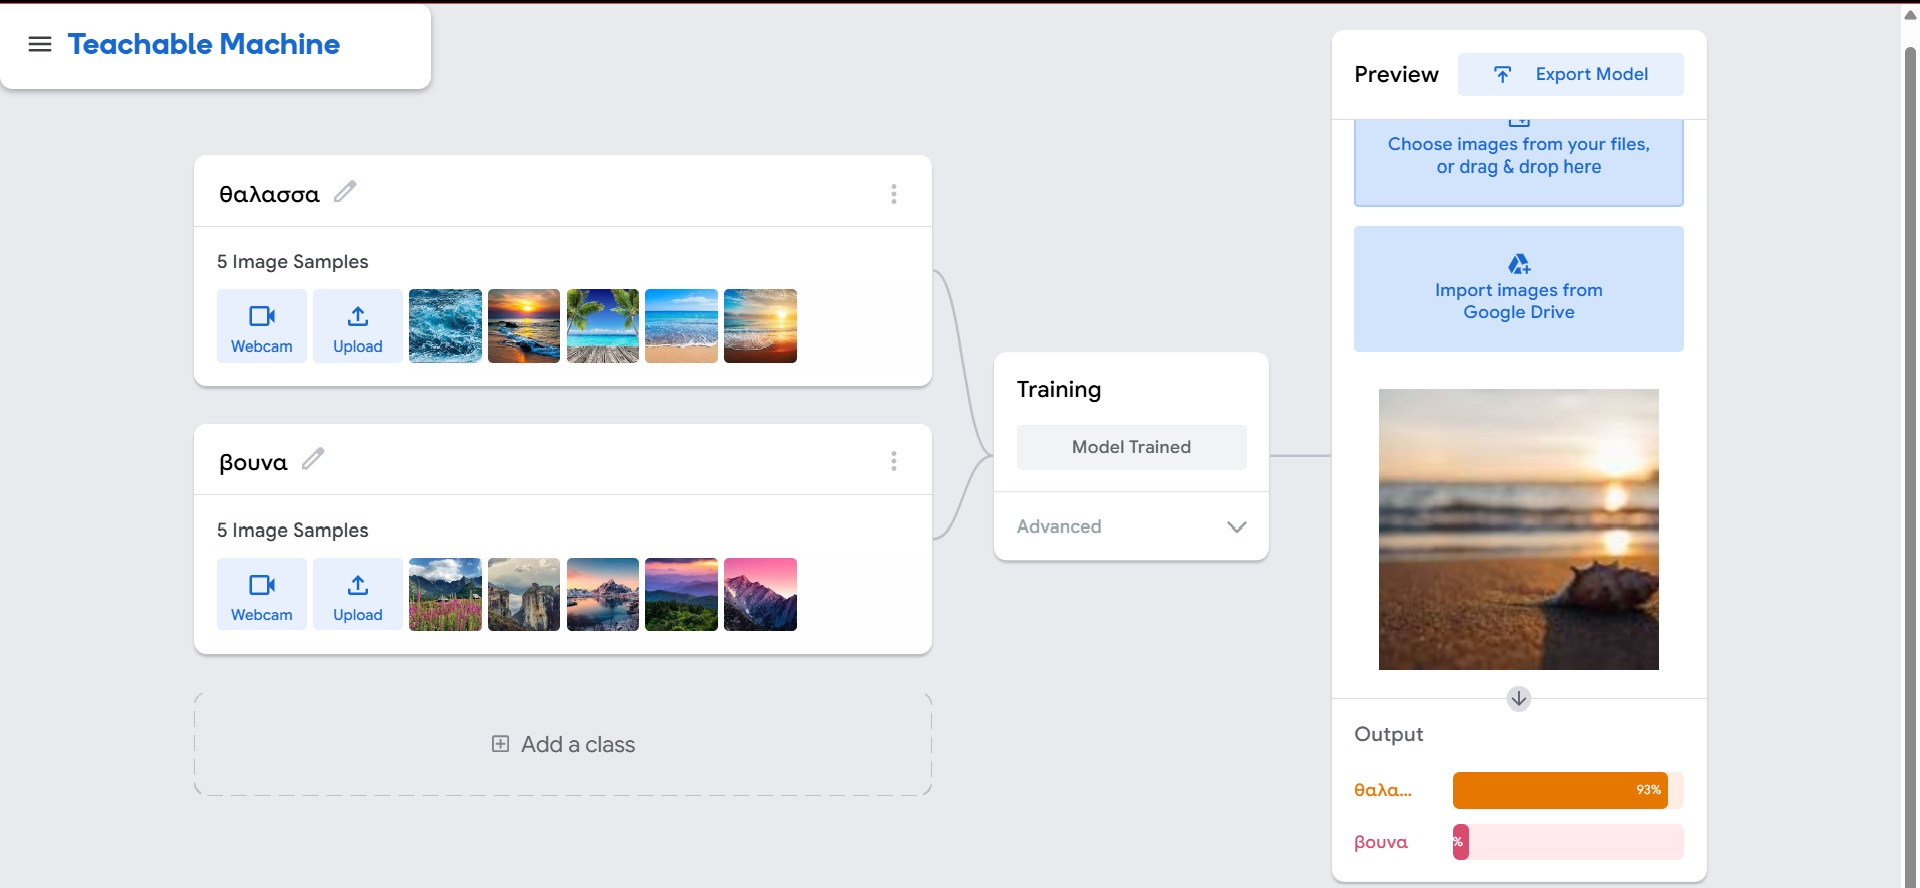

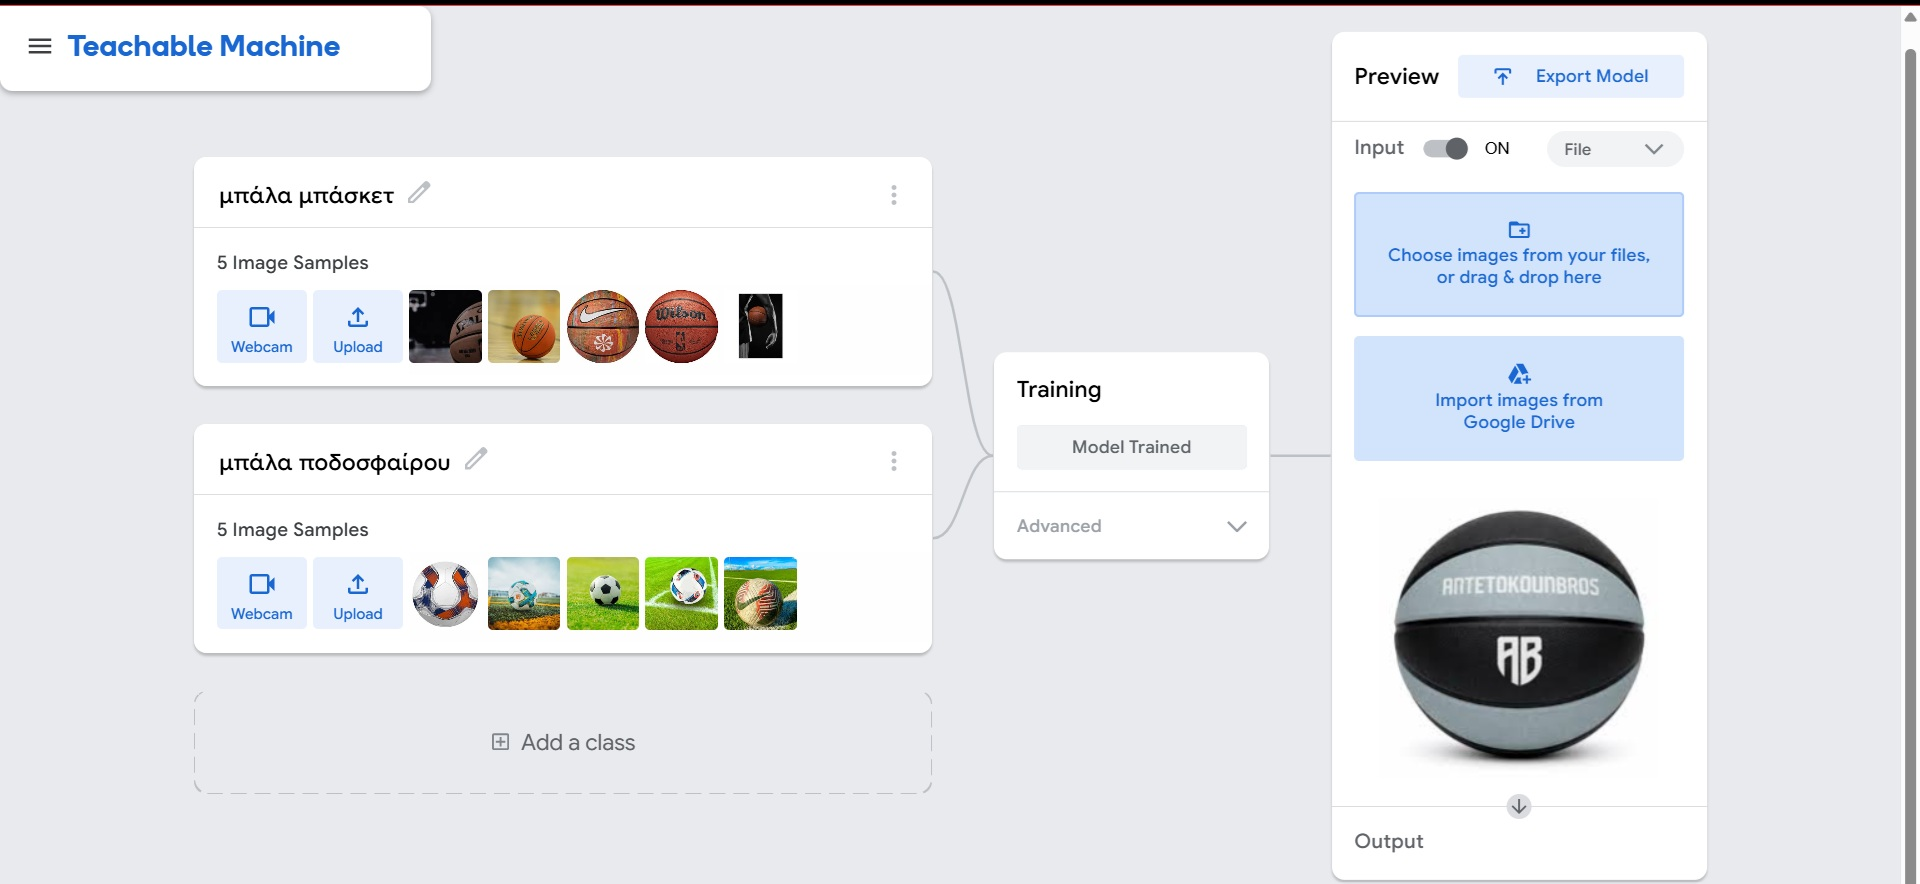